# Income analysis

We use the prepared Eurostat data to compare income across countries, age groups and years. This notebook contains the analysis, visualisations and discussion of the findings, starting with Greece.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter

In [3]:
df_clean = pd.read_csv("../data/processed/ilc_di03_clean.csv")
df_age = pd.read_csv("../data/processed/ilc_di03_age_groups.csv")

In [4]:
# Restore the age order, which is not stored in CSV files.
df_age["age_group"] = pd.Categorical(
    df_age["age_group"],
    categories=["0–17", "18–24", "25–49", "50–64", "65+"],
    ordered=True)

df_clean.shape, df_age.shape

((101948, 14), (23170, 10))

In [5]:
# Create a separate table without changing df_clean.
greece_income = df_clean.loc[
    (df_clean["geo_code"] == "EL")       # Greece
    & (df_clean["sex"] == "T")           # Total population
    & (df_clean["age"] == "TOTAL")       # All ages
    & (df_clean["unit"] == "EUR")
    & df_clean["indicator"].isin(["MEAN_EI", "MED_EI"]),
    ["year", "indicator", "income", "obs_flag"]
].copy()

greece_income.head()

,year,indicator,income,obs_flag
261,2003,MEAN_EI,9675,b
262,2004,MEAN_EI,10199,NaN
263,2005,MEAN_EI,11149,NaN
264,2006,MEAN_EI,11666,NaN
265,2007,MEAN_EI,12130,NaN


### Income reference year

For Greece, income refers to the calendar year before the survey. We keep `year` as the survey year and use `income_year` for the charts, covering 2002–2024.

Source: [ELSTAT, EU-SILC 2025, explanatory notes, p. 14](https://www.statistics.gr/documents/20181/30dc21b1-d0b6-feb9-beca-62e75e6b0d86). We use this definition to align income with historical events.

In [6]:
# Greek income refers to the calendar year before the survey.
greece_income["income_year"] = greece_income["year"] - 1

# Put mean and median in separate columns without calculating new averages.
income_plot = greece_income.pivot(
    index="income_year",
    columns="indicator",
    values="income"
).sort_index()

income_plot.head()

indicator,MEAN_EI,MED_EI
income_year,,
2002,9675,8206
2003,10199,8844
2004,11149,9417
2005,11666,9850
2006,12130,10200


### Government background

Source: [Greek government archive](https://gslegal.gov.gr/kyvernisi/istorika-stoixeia/?sort=time). We use the government dates to define the background periods.

Colours follow the leading party: green for PASOK, blue for New Democracy and red for SYRIZA. Papademos and caretaker governments are grey. Coalition details will appear in the chart notes.

The shading provides historical context and does not establish causation.

In [7]:
background_colors = {
    "PASOK": "#E5F0E7",
    "ND": "#E6EDF8",
    "SYRIZA": "#F6E5E6",
    "Other": "#DDE0E5"}

In [8]:
# Each entry contains: start date, end date, background category.
# The first and last dates are clipped to the chart window.
government_periods = [
    ("2002-01-01", "2004-03-10", "PASOK"),
    ("2004-03-10", "2009-10-06", "ND"),
    ("2009-10-06", "2011-11-11", "PASOK"),
    ("2011-11-11", "2012-05-16", "Other"),  # Papademos
    ("2012-05-16", "2012-06-20", "Other"),  # Pikrammenos, caretaker
    ("2012-06-20", "2015-01-26", "ND"),
    ("2015-01-26", "2015-08-27", "SYRIZA"),
    ("2015-08-27", "2015-09-21", "Other"),  # Thanou, caretaker
    ("2015-09-21", "2019-07-08", "SYRIZA"),
    ("2019-07-08", "2023-05-25", "ND"),
    ("2023-05-25", "2023-06-26", "Other"),  # Sarmas, caretaker
    ("2023-06-26", "2025-01-01", "ND")]

### Memorandum markers

We use the following MoU signature dates for the chart’s vertical markers:

- **3 May 2010:** [European Commission, paragraph 13](https://ec.europa.eu/competition/state_aid/cases/241369/241369_1981018_290_2.pdf).
- **14 March 2012:** [Council of the EU, document 11256/12, paragraph 10](https://register.consilium.europa.eu/pdf/en/12/st11/st11256.en12.pdf).
- **19 August 2015:** [European Commission, “Launch of the programme”](https://economy-finance.ec.europa.eu/eu-financial-assistance/euro-area-countries/financial-assistance-greece_en).

We use these sources only for the signature dates.

In [9]:
# Each entry contains the signature date and its chart label.
# \n places the date on a new line.
memoranda = [
    ("2010-05-03", "1st MoU\n3 May 2010"),
    ("2012-03-14", "2nd MoU\n14 Mar 2012"),
    ("2015-08-19", "3rd MoU\n19 Aug 2015")]

### Coalition labels

The notes identify ND-led coalitions in 2012–2015 and SYRIZA–ANEL in January–August 2015 and September 2015–January 2019.

Sources: [ECA programme timeline](https://op.europa.eu/webpub/eca/special-reports/greek-crisis-17-2017/en/), [IPU, January 2015 election](https://data.ipu.org/election-summary/HTML/2125_15_Jan.htm), and [European Parliament, Greece country sheet, p. 35](https://www.europarl.europa.eu/pdfs/news/expert/2019/5/background/20190516BKG51011/20190516BKG51011_en.pdf#page=35).

These sources support the coalition labels. Government boundaries follow the Greek government archive cited above.

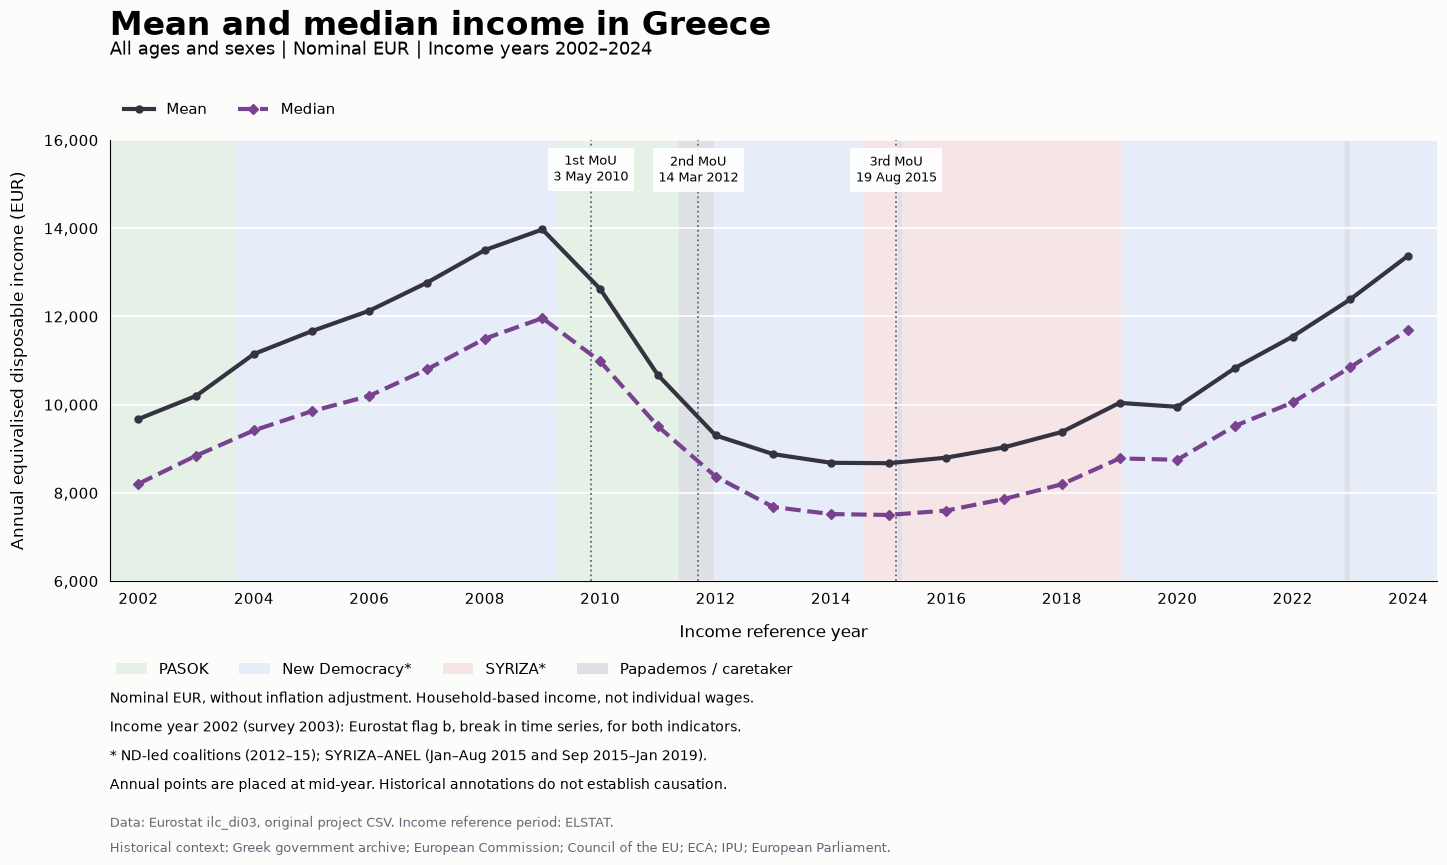

In [11]:
# Place annual observations at mid-year for plotting.
# This is a display convention, not an exact measurement date.
plot_dates = pd.to_datetime(income_plot.index.astype(str) + "-07-01")

fig, ax = plt.subplots(figsize=(15, 9), facecolor="#FCFCFA")

# Leave space for the title, legends and notes.
fig.subplots_adjust(left=0.08, right=0.965, top=0.82, bottom=0.33)

# Draw the government backgrounds behind the income lines.
for start, end, party in government_periods:
    ax.axvspan(
        pd.Timestamp(start), pd.Timestamp(end),
        color=background_colors[party], zorder=0)

ax.plot(
    plot_dates, income_plot["MEAN_EI"],
    color="#34333F", linestyle="-", linewidth=3,
    marker="o", markersize=5, label="Mean", zorder=3)

ax.plot(
    plot_dates, income_plot["MED_EI"],
    color="#79428E", linestyle="--", linewidth=3,
    marker="D", markersize=5, label="Median", zorder=3)

for date, label in memoranda:
    date = pd.Timestamp(date)
    ax.axvline(
        date, color="#626875", linestyle=":", linewidth=1.3, zorder=2)

    # Keep the date on the x-axis and the label at 97% of the chart height.
    ax.text(
        date, 0.97, label, transform=ax.get_xaxis_transform(),
        ha="center", va="top", fontsize=9.5,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
        zorder=4)

# Show a tick every two income years.
ax.set_xticks(plot_dates[::2])
ax.set_xticklabels(income_plot.index[::2])

ax.set_xlim(pd.Timestamp("2002-01-01"), pd.Timestamp("2025-01-01"))
ax.set_ylim(6000, 16000)
ax.set_yticks(range(6000, 16001, 2000))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax.set_xlabel("Income reference year", fontsize=12, labelpad=12)
ax.set_ylabel(
    "Annual equivalised disposable income (EUR)",
    fontsize=12, labelpad=12)

ax.tick_params(axis="both", labelsize=11, length=0, pad=8)
ax.grid(axis="y", color="white", linewidth=1.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    loc="lower left", bbox_to_anchor=(0, 1.02),
    ncol=2, frameon=False, fontsize=11)

fig.suptitle(
    "Mean and median income in Greece",
    x=0.08, y=0.965, ha="left", fontsize=24, fontweight="bold")
fig.text(
    0.08, 0.915,
    "All ages and sexes | Nominal EUR | Income years 2002–2024",
    fontsize=13)

# Use coloured boxes to explain the government backgrounds.
government_legend = [
    Patch(facecolor=background_colors["PASOK"], label="PASOK"),
    Patch(facecolor=background_colors["ND"], label="New Democracy*"),
    Patch(facecolor=background_colors["SYRIZA"], label="SYRIZA*"),
    Patch(facecolor=background_colors["Other"], label="Papademos / caretaker")]

fig.legend(
    handles=government_legend, loc="upper left",
    bbox_to_anchor=(0.075, 0.255),
    ncol=4, frameon=False, fontsize=11)

# Figure coordinates run from 0 to 1.
# These positions place the notes below the chart.
fig.text(
    0.08, 0.195,
    "Nominal EUR, without inflation adjustment. Household-based income, not individual wages.",
    fontsize=10)
fig.text(
    0.08, 0.163,
    "Income year 2002 (survey 2003): Eurostat flag b, break in time series, for both indicators.",
    fontsize=10)
fig.text(
    0.08, 0.131,
    "* ND-led coalitions (2012–15); SYRIZA–ANEL (Jan–Aug 2015 and Sep 2015–Jan 2019).",
    fontsize=10)
fig.text(
    0.08, 0.099,
    "Annual points are placed at mid-year. Historical annotations do not establish causation.",
    fontsize=10)
fig.text(
    0.08, 0.057,
    "Data: Eurostat ilc_di03, original project CSV. Income reference period: ELSTAT.",
    fontsize=9, color="#626875")
fig.text(
    0.08, 0.029,
    "Historical context: Greek government archive; European Commission; "
    "Council of the EU; ECA; IPU; European Parliament.",
    fontsize=9, color="#626875")

fig.savefig(
    "../reports/figures/greece_income_mean_median.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

In [12]:
# idxmax/idxmin return the year; max/min return the income value.
# income_plot is sorted by year, so its last row is the latest year.
income_summary = pd.DataFrame({
    "Peak year": income_plot.idxmax(),
    "Peak income (EUR)": income_plot.max(),
    "Lowest year": income_plot.idxmin(),
    "Lowest income (EUR)": income_plot.min(),
    "Latest year": income_plot.index[-1],
    "Latest income (EUR)": income_plot.iloc[-1]})

income_summary = income_summary.rename(index={"MEAN_EI": "Mean", "MED_EI": "Median"})

income_summary

,Peak year,Peak income (EUR),Lowest year,Lowest income (EUR),Latest year,Latest income (EUR)
indicator,,,,,,
Mean,2009,13974,2015,8673,2024,13381
Median,2009,11963,2015,7500,2024,11700


### Mean–median income gap

Greece, all ages and sexes, equivalised disposable income in nominal EUR.

**Gap (%) = (mean − median) / median × 100**

| Income year | Mean (€) | Median (€) | Mean above median |
|---|---:|---:|---:|
| 2009 | 13,974 | 11,963 | 16.81% |
| 2015 | 8,673 | 7,500 | 15.64% |
| 2024 | 13,381 | 11,700 | 14.37% |

Very high incomes can pull the mean upwards, while the median is less sensitive to their size ([NIST](https://www.itl.nist.gov/div898/handbook/eda/section3/eda351.htm)). This is a plausible explanation, but these summaries cannot show how many people have low or very high incomes.

Employment, capital income, taxes and transfers also shape income distribution ([OECD, 2012](https://www.oecd.org/content/dam/oecd/en/publications/reports/2012/01/less-income-inequality-and-more-growth-are-they-compatible-part-1-mapping-income-inequality-across-the-oecd_g17a20b6/5k9h297wxbnr-en.pdf)). Their contribution to the Greek gap remains unverified.

In [13]:
# Compare the end of each period with its starting value.
income_changes = pd.DataFrame({
    "2009–2015 (EUR)": income_plot.loc[2015] - income_plot.loc[2009],
    "2009–2015 (%)": (income_plot.loc[2015] / income_plot.loc[2009] - 1) * 100,
    "2015–2024 (EUR)": income_plot.loc[2024] - income_plot.loc[2015],
    "2015–2024 (%)": (income_plot.loc[2024] / income_plot.loc[2015] - 1) * 100,
    "2009–2024 (EUR)": income_plot.loc[2024] - income_plot.loc[2009],
    "2009–2024 (%)": (income_plot.loc[2024] / income_plot.loc[2009] - 1) * 100})

income_changes = income_changes.rename(
    index={"MEAN_EI": "Mean", "MED_EI": "Median"})

# Round only the displayed result.
income_changes.round(2)

,2009–2015 (EUR),2009–2015 (%),2015–2024 (EUR),2015–2024 (%),2009–2024 (EUR),2009–2024 (%)
indicator,,,,,,
Mean,-5301,-37.93,4708,54.28,-593,-4.24
Median,-4463,-37.31,4200,56.00,-263,-2.20


Nominal income changes in Greece

For all ages and sexes, mean equivalised disposable income fell 37.93% between income years 2009 and 2015; median income fell 37.31%.

Between 2015 and 2024, mean income increased 54.28% and median income 56.00%. Despite this recovery, both remained below their 2009 peaks: mean by €593 (4.24%) and median by €263 (2.20%).

These are cumulative changes in nominal EUR. They do not account for inflation or establish a recovery in purchasing power.

Income in Greece by age group

Mean and median equivalised disposable income for five age groups, all sexes, in nominal EUR.

Legend: Colours identify age groups. Mean uses solid lines; median uses dashed lines. Both panels share the same income scale.

Notes: Income years 2002–2024 correspond to surveys 2003–2025 (ELSTAT, p. 14). Income year 2002 retains flag b (break in time series) for every group and both indicators. Amounts are not adjusted for inflation.

Government shading and MoU markers follow the sources documented above.

In [14]:
greece_age = df_age.loc[
    (df_age["geo_code"] == "EL")
    & (df_age["sex"] == "T")
    & (df_age["unit"] == "EUR")
    & df_age["indicator"].isin(["MEAN_EI", "MED_EI"])].copy()

greece_age["income_year"] = greece_age["year"] - 1

In [15]:
# Reshape the published values without calculating new means or medians.
age_mean = greece_age.loc[greece_age["indicator"] == "MEAN_EI"].pivot(
    index="income_year", columns="age_group", values="income").sort_index()

age_median = greece_age.loc[greece_age["indicator"] == "MED_EI"].pivot(
    index="income_year", columns="age_group", values="income").sort_index()

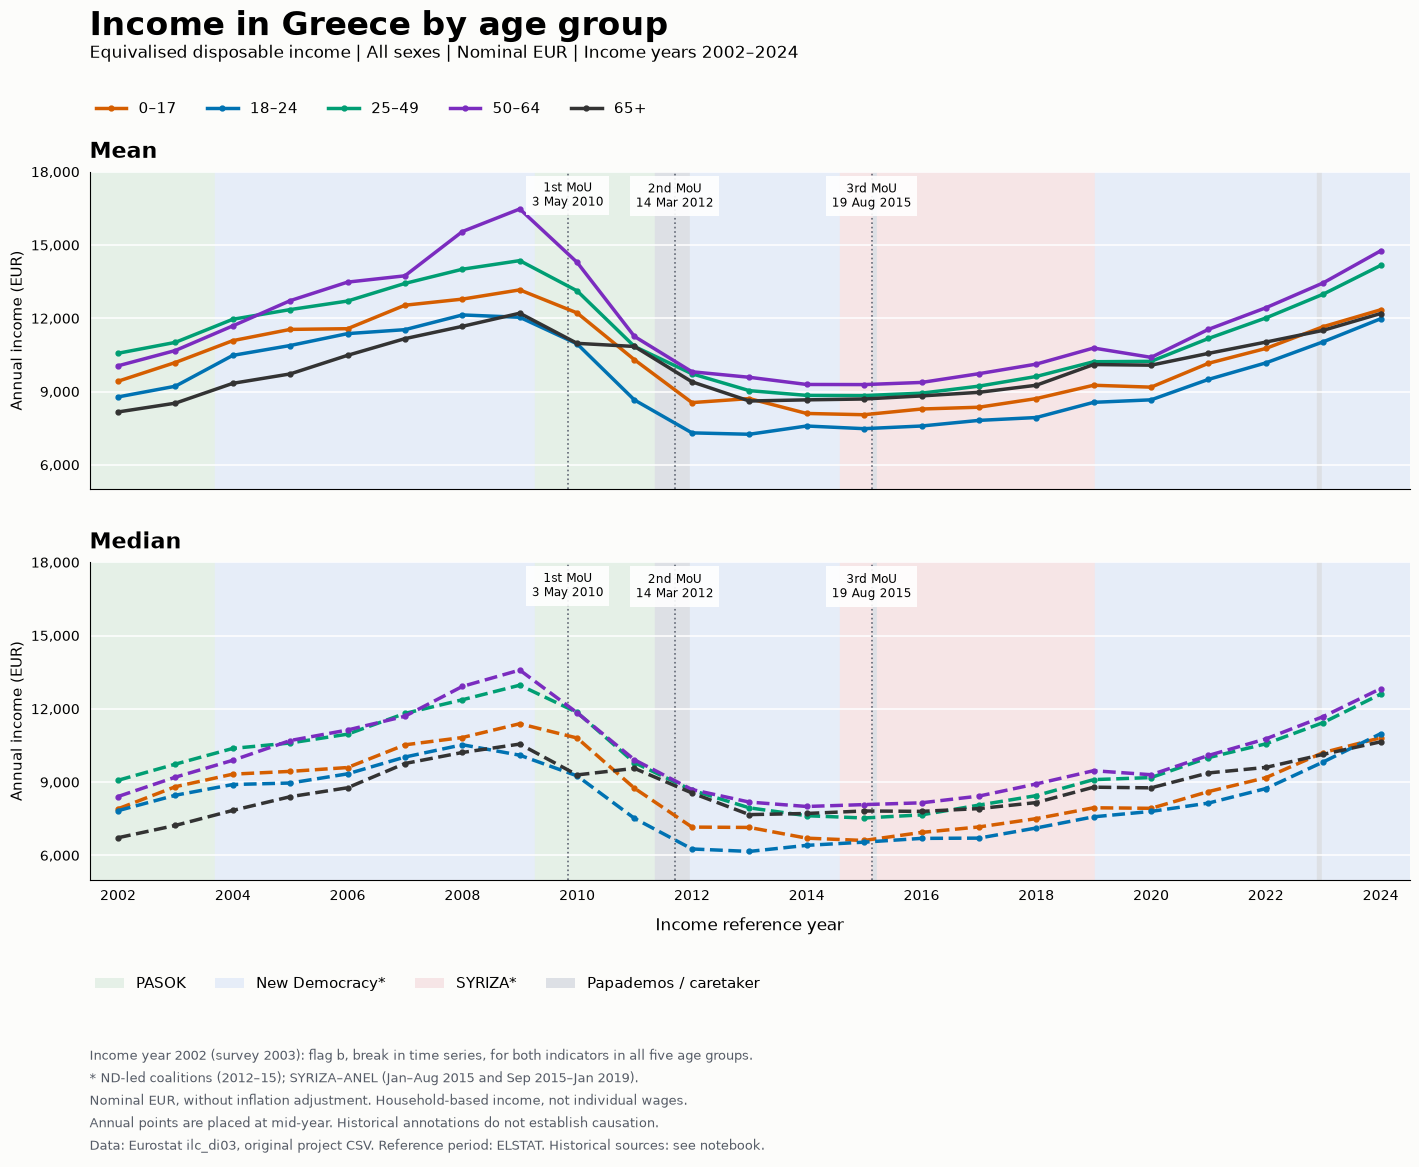

In [16]:
age_colors = {
    "0–17": "#D55E00",
    "18–24": "#0072B2",
    "25–49": "#009E73",
    "50–64": "#7B2CBF",
    "65+": "#333333"}

# Mid-year placement is a plotting convention, not a measurement date.
age_dates = pd.to_datetime(age_mean.index.astype(str) + "-07-01")

# Both panels use the same time axis and income scale.
fig, axes = plt.subplots(
    2, 1, figsize=(15, 12), sharex=True, sharey=True, facecolor="#FCFCFA")
fig.subplots_adjust(
    left=0.09, right=0.97, top=0.84, bottom=0.25, hspace=0.23)

# Pair each panel with its table, title and line style.
for ax, data, title, style in [
    (axes[0], age_mean, "Mean", "-"),
    (axes[1], age_median, "Median", "--")
]:
    for start, end, party in government_periods:
        ax.axvspan(
            pd.Timestamp(start), pd.Timestamp(end),
            color=background_colors[party], zorder=0
        )

    for group, color in age_colors.items():
        ax.plot(
            age_dates, data[group],
            color=color, linestyle=style, linewidth=2.5,
            marker="o", markersize=3.5, label=group, zorder=3
        )

    for date, label in memoranda:
        date = pd.Timestamp(date)
        ax.axvline(
            date, color="#626875", linestyle=":", linewidth=1.2
        )

        # Keep the label near the top, regardless of the income values.
        ax.text(
            date, 0.97, label,
            transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=8.5,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.9,
            },
            zorder=4
        )

    ax.set_title(
        title, loc="left", fontsize=16, fontweight="bold", pad=10
    )
    ax.set_ylim(5000, 18000)
    ax.set_yticks(range(6000, 18001, 3000))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_ylabel("Annual income (EUR)", fontsize=11)
    ax.grid(axis="y", color="white", linewidth=1.1)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="both", labelsize=10, length=0, pad=7)

axes[1].set_xticks(age_dates[::2])
axes[1].set_xticklabels(age_mean.index[::2])
axes[1].set_xlim(pd.Timestamp("2002-01-01"), pd.Timestamp("2025-01-01"))
axes[1].set_xlabel("Income reference year", fontsize=12, labelpad=10)

fig.suptitle(
    "Income in Greece by age group",
    x=0.09, y=0.975, ha="left", fontsize=24, fontweight="bold")
fig.text(
    0.09, 0.935,
    "Equivalised disposable income | All sexes | Nominal EUR | "
    "Income years 2002–2024",
    fontsize=12)

# Use one age-group legend for both panels.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper left", bbox_to_anchor=(0.085, 0.91),
    ncol=5, frameon=False, fontsize=11)

# Reuse the government legend from the previous chart.
fig.legend(
    handles=government_legend,
    loc="upper left", bbox_to_anchor=(0.085, 0.18),
    ncol=4, frameon=False, fontsize=10.5)

fig.text(
    0.09, 0.025,
    "Income year 2002 (survey 2003): flag b, break in time series, "
    "for both indicators in all five age groups.\n"
    "* ND-led coalitions (2012–15); "
    "SYRIZA–ANEL (Jan–Aug 2015 and Sep 2015–Jan 2019).\n"
    "Nominal EUR, without inflation adjustment. "
    "Household-based income, not individual wages.\n"
    "Annual points are placed at mid-year. "
    "Historical annotations do not establish causation.\n"
    "Data: Eurostat ilc_di03, original project CSV. "
    "Reference period: ELSTAT. Historical sources: see notebook.",
    fontsize=9, linespacing=1.8, color="#555B66")

# Save the figure before displaying it.
fig.savefig(
    "../reports/figures/greece_income_by_age_mean_median.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

In [17]:
# Put each age group and indicator on a separate row.
age_comparison = greece_age.loc[
    greece_age["income_year"].isin([2009, 2015, 2024])
].pivot(
    index=["age_group", "indicator"],
    columns="income_year",
    values="income"
).sort_index()

# Each percentage uses the first year of the period as its base.
age_comparison["2009–2015 (%)"] = (age_comparison[2015] / age_comparison[2009] - 1) * 100

age_comparison["2015–2024 (%)"] = (age_comparison[2024] / age_comparison[2015] - 1) * 100

age_comparison["2009–2024 (%)"] = (age_comparison[2024] / age_comparison[2009] - 1) * 100

# Rename only the indicator level of the row index.
age_comparison = age_comparison.rename(
    index={"MEAN_EI": "Mean", "MED_EI": "Median"},
    level="indicator")

age_comparison.columns.name = None
age_comparison.round(2)

2009  2015   2024  2009–2015 (%)  2015–2024 (%)  \
age_group indicator                                                     
0–17      Mean       13163  8051  12347         -38.84          53.36   
          Median     11389  6608  10813         -41.98          63.63   
18–24     Mean       12041  7480  11981         -37.88          60.17   
          Median     10100  6540  10981         -35.25          67.91   
25–49     Mean       14361  8835  14164         -38.48          60.32   
          Median     12967  7529  12600         -41.94          67.35   
50–64     Mean       16476  9285  14762         -43.65          58.99   
          Median     13586  8077  12824         -40.55          58.77   
65+       Mean       12208  8695  12195         -28.78          40.25   
          Median     10555  7816  10648         -25.95          36.23   

                     2009–2024 (%)  
age_group indicator                 
0–17      Mean               -6.20  
          Median             -5.06  
18–24     Mean               -0.50  
          Median              8.72  
25–49     Mean               -1.37  
          Median             -2.83  
50–64     Mean              -10.40  
          Median             -5.61  
65+       Mean               -0.11  
          Median              0.88

### Income changes by age group in Greece

Between 2009 and 2015, the largest percentage fall in mean income was among people aged **50–64 (43.65%)**. Median income fell by approximately **42%** in both the **0–17** and **25–49** groups.

In 2024, mean income remained below its 2009 level in all five groups. Median income exceeded its 2009 level for **18–24 (+8.72%)** and **65+ (+0.88%)**.

These comparisons use fixed income years, rather than each group’s own peak and lowest point. Amounts remain nominal, without inflation adjustment.

### Reading the recovery figures

The **65+** group had the smallest percentage declines between 2009 and 2015: **28.78% in mean** and **25.95% in median income**. Its smaller increases after 2015 should be considered alongside these smaller initial losses.

Percentage falls and rebounds use different starting values and cannot be added. For **50–64**, mean income fell **43.65%**, then rose **58.99%**, yet remained **10.40% below its 2009 level** in 2024.

These comparisons remain in nominal EUR, without inflation adjustment.